# Чекпойнт 2. Разведочный анализ данных (EDA)

**Проект:** AutoML для временных рядов с использованием глубокого обучения  
**Тема:** прогнозирование стоимости криптовалют и торговых сигналов  
**Автор:** Курлянд Тимофей Александрович  
**Куратор:** Дмитрий Янышев

Цель анализа — проверить качество минутных OHLCV-данных Binance, исследовать распределения цен и доходностей, стационарность рядов, автокорреляции и взаимосвязи между BTC, ETH, BNB и SOL. Анализ выполняется только на закрытых свечах и не использует будущую информацию.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss

warnings.simplefilter("ignore", InterpolationWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "raw"
SYMBOLS = ["BTC-USDT", "ETH-USDT", "BNB-USDT", "SOL-USDT"]
DISPLAY_NAMES = {symbol: symbol.replace("-", "/") for symbol in SYMBOLS}
COLORS = dict(zip(SYMBOLS, sns.color_palette("tab10", len(SYMBOLS)), strict=True))

print(f"Корень проекта: {PROJECT_ROOT}")
print(f"Каталог данных: {DATA_ROOT}")

Корень проекта: D:\year_project
Каталог данных: D:\year_project\data\raw


In [2]:
frames = {}
for symbol in SYMBOLS:
    path = DATA_ROOT / symbol / "1m.parquet"
    frame = pd.read_parquet(path).sort_index()
    frame.index = pd.to_datetime(frame.index, utc=True)
    frame["log_close"] = np.log(frame["close"])
    frame["log_return"] = frame["log_close"].diff()
    frame["abs_return"] = frame["log_return"].abs()
    frame["range_pct"] = (frame["high"] - frame["low"]) / frame["close"].shift(1)
    frame["log_volume"] = np.log1p(frame["volume"])
    frame["volume_change"] = frame["log_volume"].diff()
    frame["rolling_volatility_60m"] = frame["log_return"].rolling(60).std()
    frames[symbol] = frame

close = pd.concat(
    {DISPLAY_NAMES[symbol]: frame["close"] for symbol, frame in frames.items()},
    axis=1,
    join="inner",
)
log_returns = np.log(close).diff().dropna()

print(f"Общий пересекающийся интервал: {close.index.min()} — {close.index.max()}")
print(f"Число синхронных минут: {len(close):,}")

Общий пересекающийся интервал: 2026-01-01 00:00:00+00:00 — 2026-10-31 14:10:00+00:00
Число синхронных минут: 437,171


## 1. Качество и покрытие данных

Проверяем период наблюдений, пропуски, дубликаты, разрывы минутной сетки, неположительные цены и свечи с нулевым объёмом.

In [3]:
quality_rows = []
for symbol, frame in frames.items():
    minute_diff = frame.index.to_series().diff()
    quality_rows.append(
        {
            "пара": DISPLAY_NAMES[symbol],
            "начало": frame.index.min(),
            "конец": frame.index.max(),
            "строк": len(frame),
            "дубликатов": int(frame.index.duplicated().sum()),
            "разрывов > 1 мин": int((minute_diff > pd.Timedelta(minutes=1)).sum()),
            "пропусков": int(frame[["open", "high", "low", "close", "volume"]].isna().sum().sum()),
            "неположительных цен": int(
                (frame[["open", "high", "low", "close"]] <= 0).any(axis=1).sum()
            ),
            "нулевой объём": int((frame["volume"] == 0).sum()),
        }
    )

quality = pd.DataFrame(quality_rows).set_index("пара")
display(quality)

critical_columns = [
    "дубликатов",
    "разрывов > 1 мин",
    "пропусков",
    "неположительных цен",
]
assert quality[critical_columns].to_numpy().sum() == 0
print("Критических дефектов данных не обнаружено.")

,начало,конец,строк,дубликатов,разрывов > 1 мин,пропусков,неположительных цен,нулевой объём
пара,,,,,,,,
BTC/USDT,2026-01-01 00:00:00+00:00,2026-10-31 14:10:00+00:00,437171,0,0,0,0,0
ETH/USDT,2026-01-01 00:00:00+00:00,2026-10-31 14:10:00+00:00,437171,0,0,0,0,0
BNB/USDT,2026-01-01 00:00:00+00:00,2026-10-31 14:11:00+00:00,437172,0,0,0,0,0
SOL/USDT,2026-01-01 00:00:00+00:00,2026-10-31 14:11:00+00:00,437172,0,0,0,0,0


Критических дефектов данных не обнаружено.


**Вывод.** Для всех четырёх пар доступен непрерывный минутный ряд с начала 2026 года. Дубликаты, пропуски OHLCV, разрывы временной сетки и неположительные цены отсутствуют. Данные можно использовать для временной валидации без искусственного заполнения пропусков. Нулевой объём, если встретится, не является пропуском: это допустимое состояние свечи без сделок.

## 2. Динамика цены и логарифмирование ряда

Абсолютные цены несопоставимы по масштабу, поэтому дополнительно рассматриваем нормированные цены и натуральный логарифм цены. Логарифмирование переводит мультипликативные изменения в аддитивные, но само по себе не гарантирует стационарность.

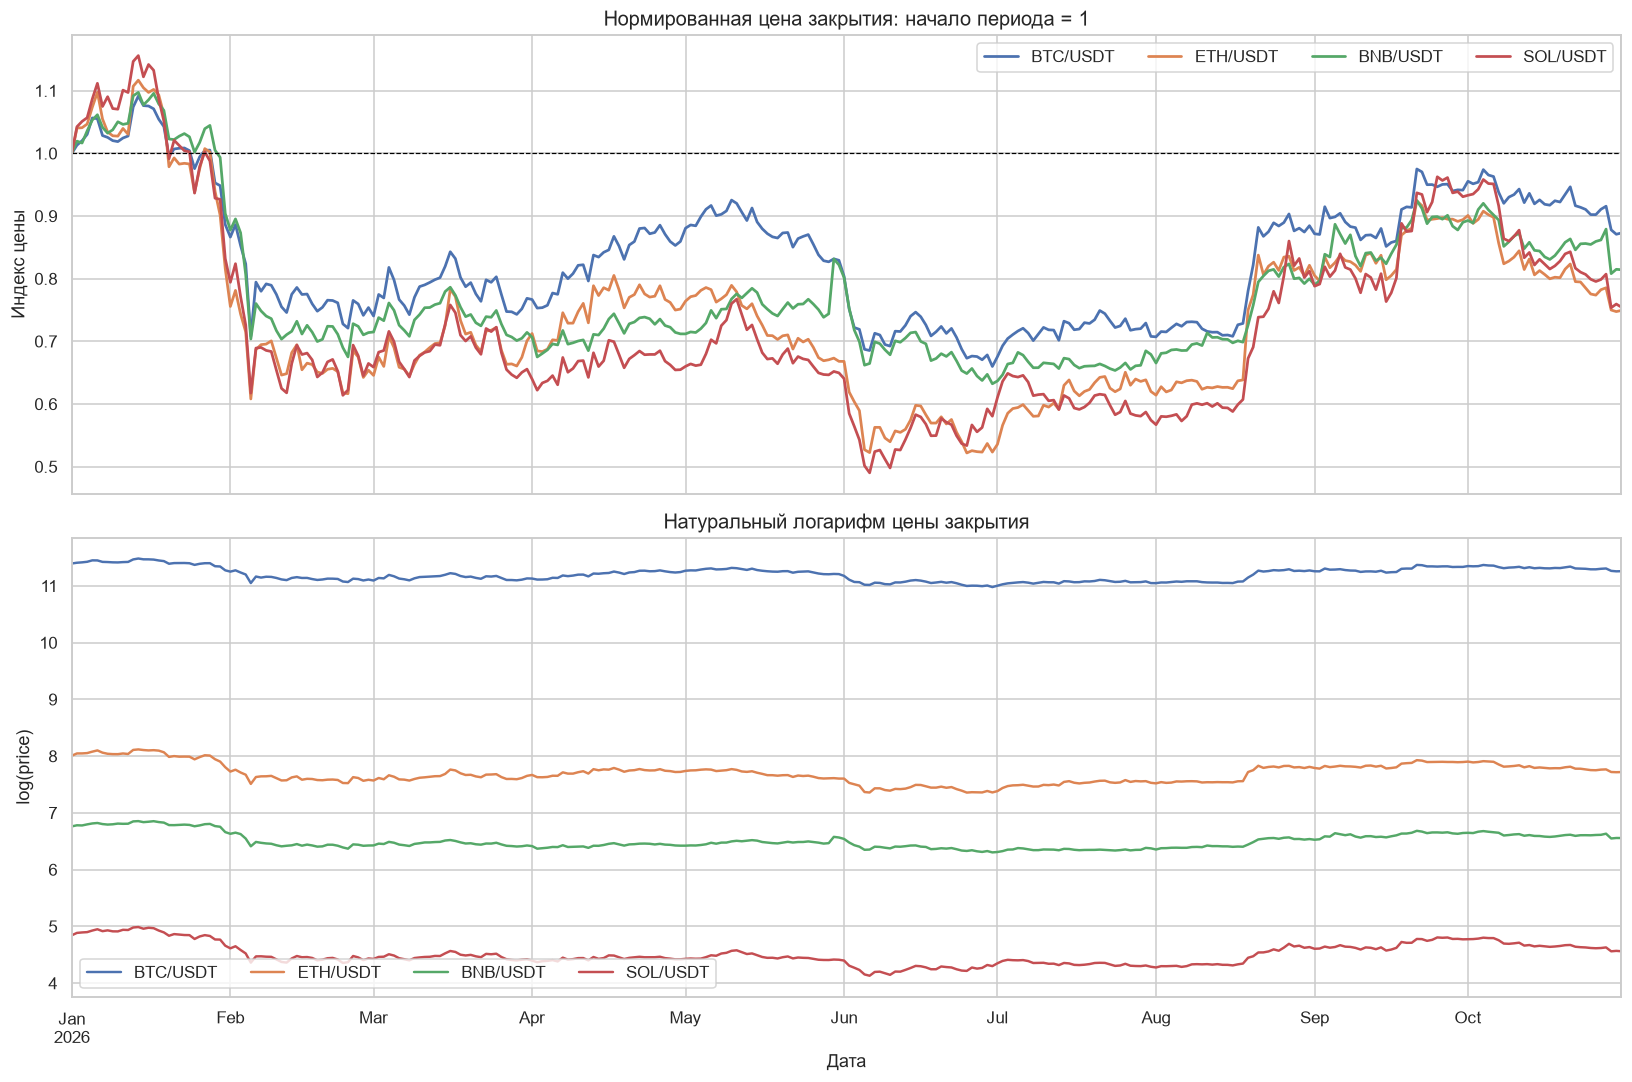

,изменение за период
BTC/USDT,-12.71%
BNB/USDT,-18.57%
SOL/USDT,-24.55%
ETH/USDT,-25.06%


In [4]:
daily_close = close.resample("1D").last().dropna()
normalized = daily_close / daily_close.iloc[0]
log_daily = np.log(daily_close)

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
normalized.plot(ax=axes[0], linewidth=1.8)
axes[0].axhline(1.0, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title("Нормированная цена закрытия: начало периода = 1")
axes[0].set_ylabel("Индекс цены")
axes[0].legend(ncol=4)

log_daily.plot(ax=axes[1], linewidth=1.6)
axes[1].set_title("Натуральный логарифм цены закрытия")
axes[1].set_ylabel("log(price)")
axes[1].set_xlabel("Дата")
axes[1].legend(ncol=4)
plt.tight_layout()
plt.show()

period_change = (daily_close.iloc[-1] / daily_close.iloc[0] - 1).sort_values(ascending=False)
display(period_change.rename("изменение за период").to_frame().style.format("{:.2%}"))

**Вывод.** За рассматриваемый период все активы снизились: BTC на 12.71%, BNB на 18.57%, SOL на 24.55%, ETH на 25.06%. Ценовые уровни демонстрируют продолжительные режимы роста и снижения. Логарифмирование уменьшает различия масштаба между активами, но `log(price)` по-прежнему не колеблется вокруг постоянного среднего. Для моделирования следует переходить к логарифмическим доходностям и формально проверить стационарность.

## 3. Логарифмические доходности

Используем минутную лог-доходность $r_t = \log(P_t) - \log(P_{t-1})$. Для читаемости гистограмм отображается центральный диапазон 0.5–99.5%, но статистики рассчитываются по полному ряду.

,mean,std,skew,kurt,min,max,annualized_vol_1m
BTC/USDT,-0.000000,0.000606,0.438807,36.374704,-0.020838,0.022993,0.439010
ETH/USDT,-0.000001,0.000810,0.605204,79.255929,-0.038216,0.044522,0.587192
BNB/USDT,-0.000000,0.000605,-0.071891,57.364161,-0.026511,0.024664,0.438296
SOL/USDT,-0.000001,0.000915,-0.887170,95.631751,-0.056635,0.031196,0.663249


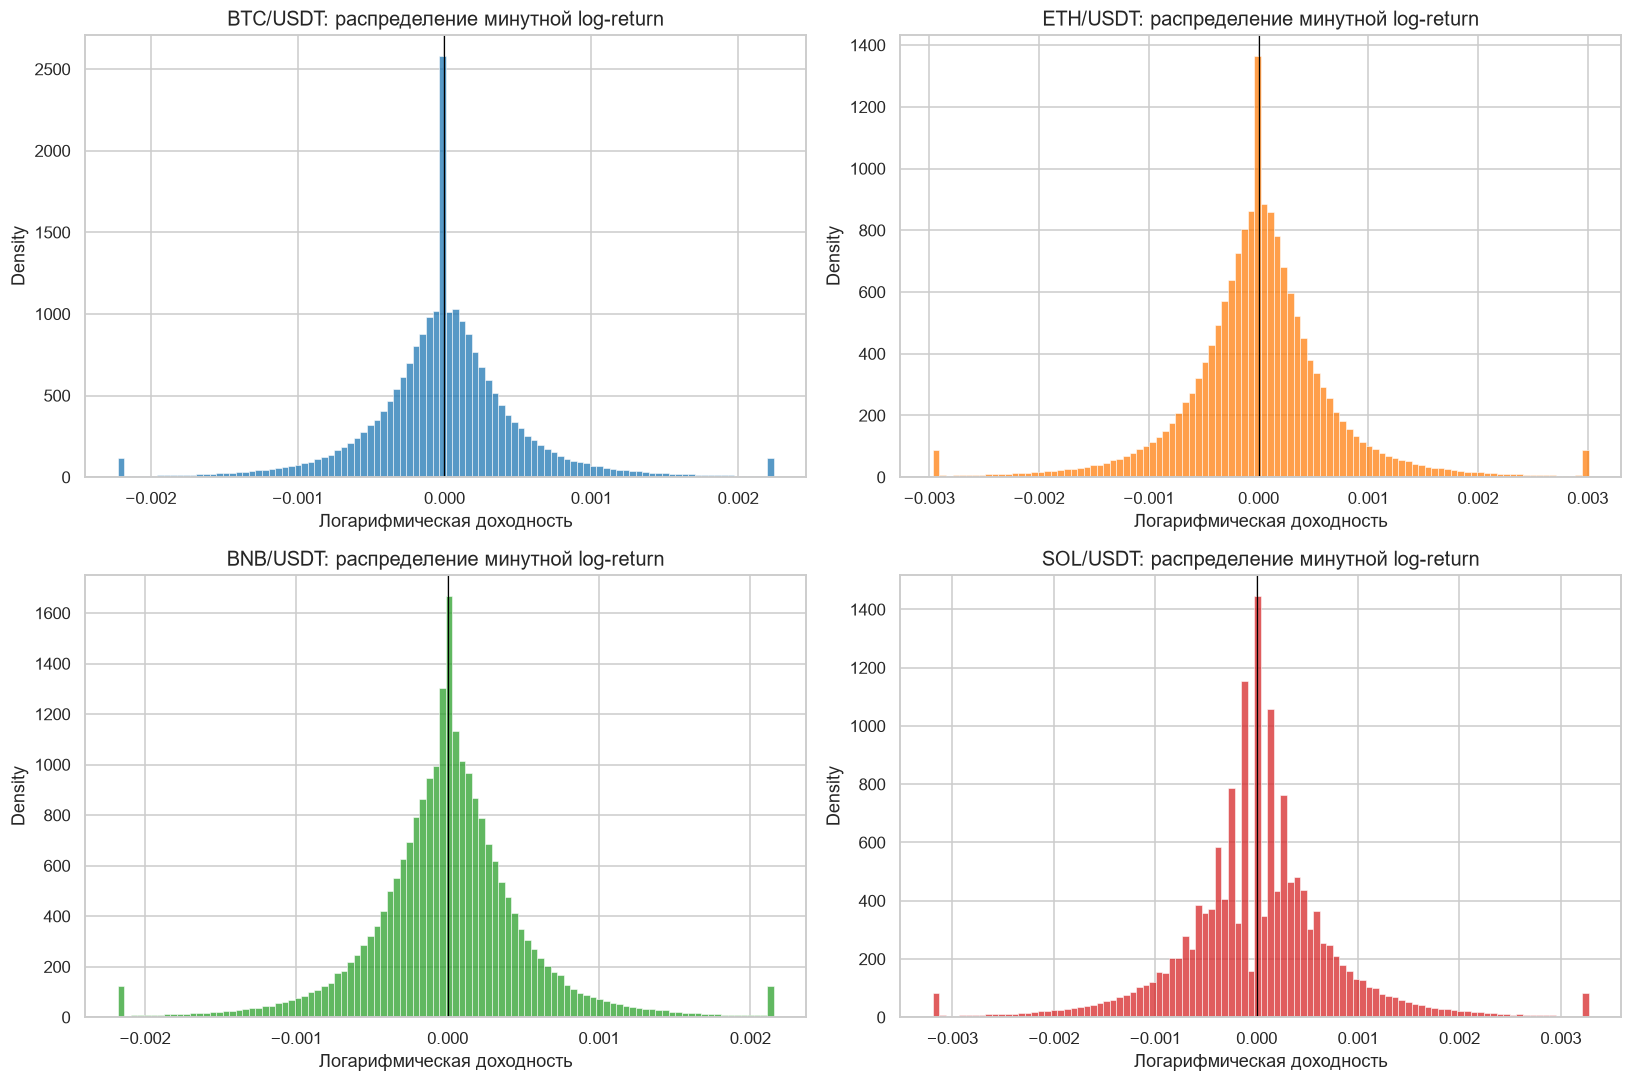

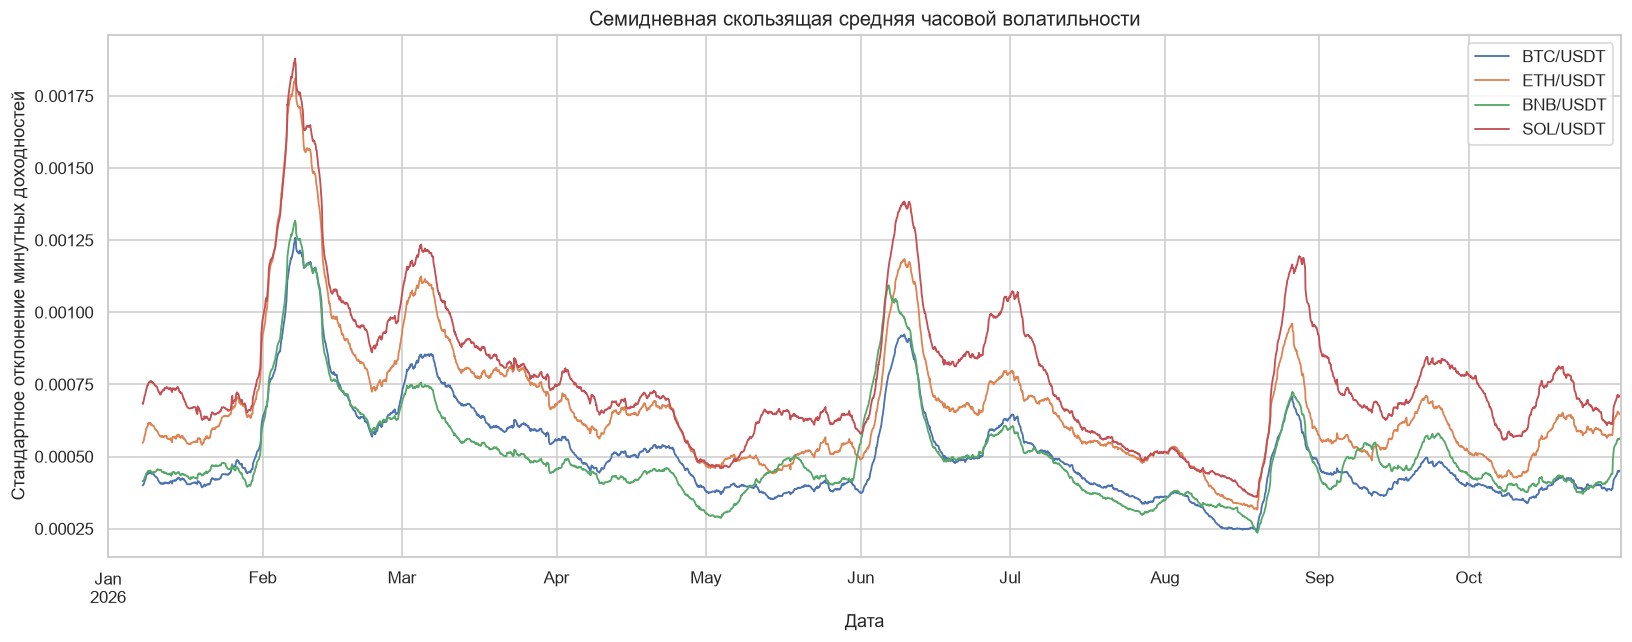

In [5]:
return_stats = log_returns.agg(["mean", "std", "skew", "kurt", "min", "max"]).T
return_stats["annualized_vol_1m"] = return_stats["std"] * np.sqrt(365 * 24 * 60)
display(return_stats.style.format("{:.6f}"))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for column, axis in zip(log_returns.columns, axes.flat, strict=True):
    series = log_returns[column]
    lower, upper = series.quantile([0.005, 0.995])
    sns.histplot(
        series.clip(lower, upper),
        bins=100,
        stat="density",
        ax=axis,
        color=COLORS[column.replace("/", "-")],
    )
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set_title(f"{column}: распределение минутной log-return")
    axis.set_xlabel("Логарифмическая доходность")
plt.tight_layout()
plt.show()

hourly_volatility = log_returns.resample("1h").std()
hourly_volatility.rolling(24 * 7).mean().plot(figsize=(15, 6), linewidth=1.2)
plt.title("Семидневная скользящая средняя часовой волатильности")
plt.ylabel("Стандартное отклонение минутных доходностей")
plt.xlabel("Дата")
plt.tight_layout()
plt.show()

**Вывод.** Среднее минутных доходностей практически равно нулю. Эксцесс находится в диапазоне 36–96 вместо нуля для нормального распределения, то есть присутствуют тяжёлые хвосты и экстремальные наблюдения. SOL имеет наибольшую оценочную годовую волатильность (66.3%), ETH — 58.7%, BTC и BNB — около 44%. Скользящая волатильность образует кластеры. Следовательно, MSE и предположение о постоянной дисперсии недостаточны; полезны robust/quantile loss и отдельный прогноз волатильности.

## 4. Проверка стационарности: ADF и KPSS

Используются два теста с противоположными нулевыми гипотезами:

- **ADF:** $H_0$ — ряд содержит единичный корень, то есть нестационарен.
- **KPSS:** $H_0$ — ряд стационарен относительно постоянного среднего.

Чтобы тесты оставались вычислимыми и сравнимыми, используется непрерывное окно последних 100 000 минут. Уровень значимости — 5%.

In [6]:
def stationarity_tests(series: pd.Series, max_observations: int = 100_000) -> dict:
    sample = series.dropna().iloc[-max_observations:]
    adf_result = adfuller(sample, maxlag=30, regression="c", autolag=None, result_object=False)
    kpss_result = kpss(sample, regression="c", nlags="auto", result_object=False)
    adf_stationary = adf_result[1] < 0.05
    kpss_stationary = kpss_result[1] >= 0.05
    if adf_stationary and kpss_stationary:
        conclusion = "стационарен"
    elif not adf_stationary and not kpss_stationary:
        conclusion = "нестационарен"
    else:
        conclusion = "тесты расходятся"
    return {
        "n": len(sample),
        "ADF statistic": adf_result[0],
        "ADF p-value": adf_result[1],
        "KPSS statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1],
        "вывод": conclusion,
    }


stationarity_rows = []
for symbol, frame in frames.items():
    for transformation, series in {
        "log(price)": frame["log_close"],
        "log-return": frame["log_return"],
    }.items():
        stationarity_rows.append(
            {
                "пара": DISPLAY_NAMES[symbol],
                "преобразование": transformation,
                **stationarity_tests(series),
            }
        )

stationarity = pd.DataFrame(stationarity_rows).set_index(["пара", "преобразование"])
display(
    stationarity.style.format(
        {
            "ADF statistic": "{:.4f}",
            "ADF p-value": "{:.4g}",
            "KPSS statistic": "{:.4f}",
            "KPSS p-value": "{:.4g}",
        }
    )
)

**Вывод.** Для `log(price)` всех четырёх активов ADF не отвергает единичный корень (`p = 0.15–0.52`), а KPSS отвергает стационарность (`p = 0.01`): ценовые логарифмы нестационарны. Для `log-return` ADF уверенно отвергает единичный корень (`p ≈ 0`), а KPSS не отвергает стационарность (`p = 0.10`). Оба теста согласованно подтверждают стационарность доходностей. Поэтому основной target проекта должен быть доходностью или её квантилями, а цена восстанавливается из накопленной прогнозной доходности.

## 5. Корреляция с лагами: ACF

ACF доходностей проверяет линейную предсказуемость направления. ACF абсолютных доходностей проверяет память волатильности. Рассматриваются лаги до 120 минут. При большом числе наблюдений даже очень малая корреляция статистически значима, поэтому отдельно используется практический порог $|r| \ge 0.01$.

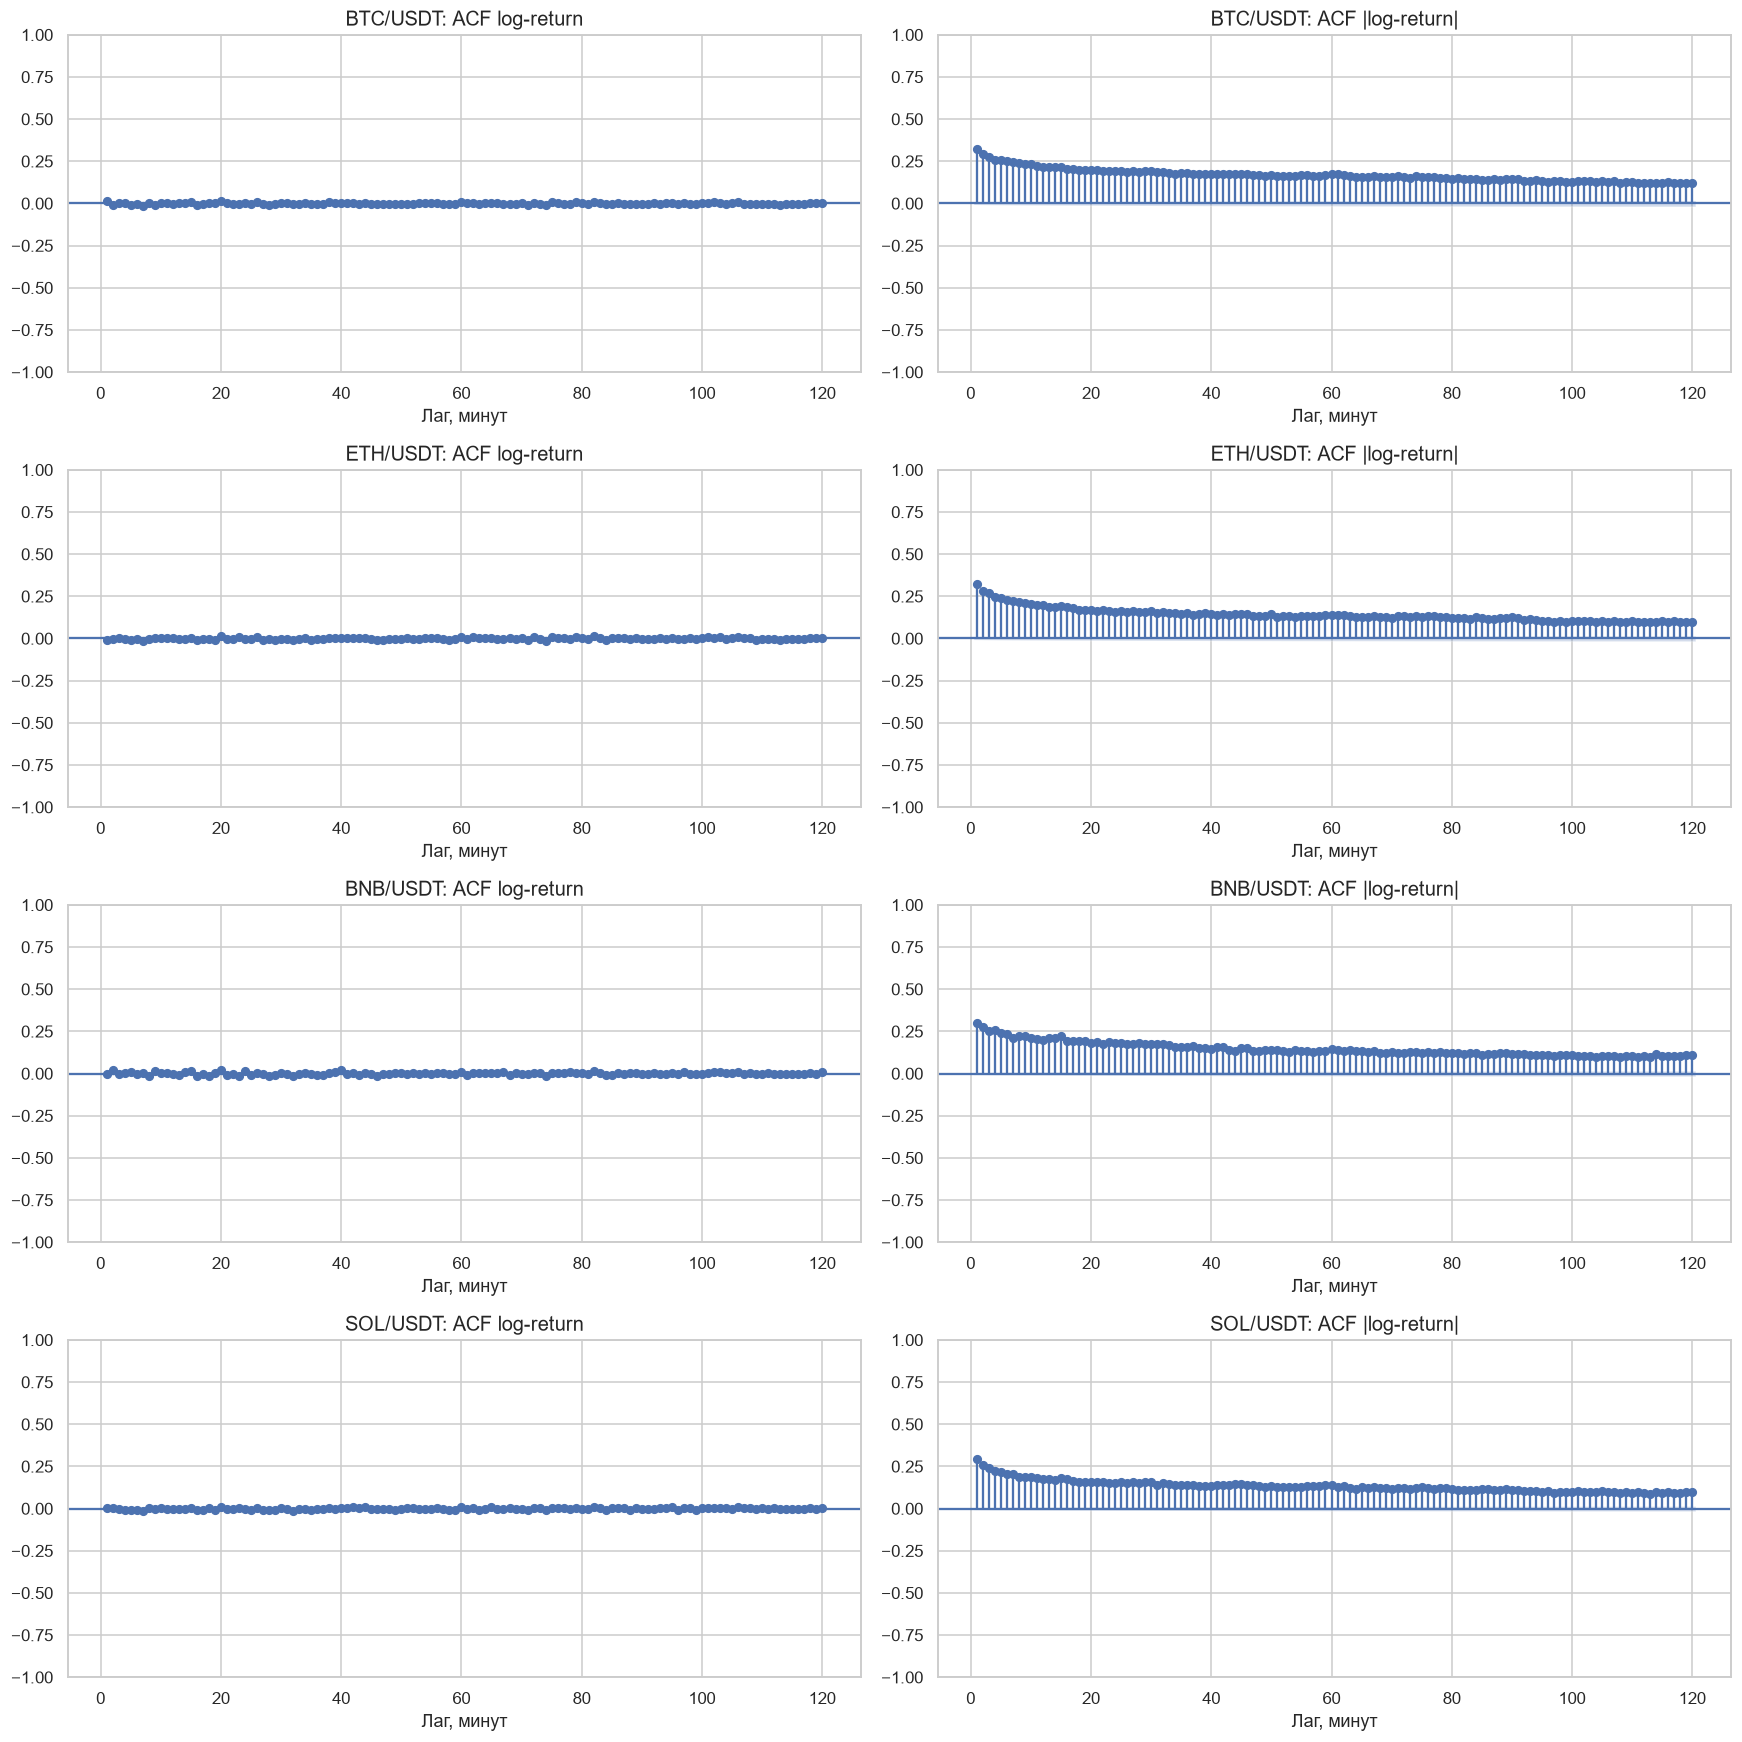

In [7]:
MAX_LAG = 120
fig, axes = plt.subplots(len(SYMBOLS), 2, figsize=(16, 16))
for row, symbol in enumerate(SYMBOLS):
    returns = frames[symbol]["log_return"].dropna().iloc[-100_000:]
    plot_acf(returns, lags=MAX_LAG, zero=False, fft=True, alpha=0.05, ax=axes[row, 0])
    axes[row, 0].set_title(f"{DISPLAY_NAMES[symbol]}: ACF log-return")
    axes[row, 0].set_xlabel("Лаг, минут")

    plot_acf(returns.abs(), lags=MAX_LAG, zero=False, fft=True, alpha=0.05, ax=axes[row, 1])
    axes[row, 1].set_title(f"{DISPLAY_NAMES[symbol]}: ACF |log-return|")
    axes[row, 1].set_xlabel("Лаг, минут")
plt.tight_layout()
plt.show()

In [8]:
lag_rows = []
for symbol in SYMBOLS:
    returns = frames[symbol]["log_return"].dropna().iloc[-100_000:]
    for series_name, series in {"return": returns, "abs(return)": returns.abs()}.items():
        values = acf(series, nlags=MAX_LAG, fft=True)[1:]
        threshold = max(1.96 / np.sqrt(len(series)), 0.01)
        significant = np.where(np.abs(values) >= threshold)[0] + 1
        ordered = sorted(significant, key=lambda lag: abs(values[lag - 1]), reverse=True)
        lag_rows.append(
            {
                "пара": DISPLAY_NAMES[symbol],
                "ряд": series_name,
                "практический порог": threshold,
                "число значимых лагов": len(significant),
                "наиболее сильные лаги": (
                    ", ".join(f"{lag} ({values[lag - 1]:+.3f})" for lag in ordered[:10]) or "нет"
                ),
            }
        )

lag_summary = pd.DataFrame(lag_rows).set_index(["пара", "ряд"])
display(lag_summary)

практический порог  число значимых лагов  \
пара     ряд                                                     
BTC/USDT return                     0.01                     5   
         abs(return)                0.01                   120   
ETH/USDT return                     0.01                     6   
         abs(return)                0.01                   120   
BNB/USDT return                     0.01                    19   
         abs(return)                0.01                   120   
SOL/USDT return                     0.01                     7   
         abs(return)                0.01                   120   

                                                  наиболее сильные лаги  
пара     ряд                                                             
BTC/USDT return       20 (+0.016), 1 (+0.013), 7 (-0.012), 74 (-0.01...  
         abs(return)  1 (+0.320), 2 (+0.291), 3 (+0.276), 4 (+0.260)...  
ETH/USDT return       20 (+0.014), 7 (-0.014), 74 (-0.013), 82 (+0.0...  
         abs(return)  1 (+0.325), 2 (+0.282), 3 (+0.267), 4 (+0.248)...  
BNB/USDT return       2 (+0.022), 20 (+0.021), 40 (+0.019), 24 (+0.0...  
         abs(return)  1 (+0.300), 2 (+0.277), 4 (+0.258), 3 (+0.251)...  
SOL/USDT return       32 (-0.014), 7 (-0.014), 20 (+0.012), 58 (-0.0...  
         abs(return)  1 (+0.293), 2 (+0.261), 3 (+0.240), 4 (+0.221)...

**Вывод.** У доходностей практический порог `|r| ≥ 0.01` превышают только 5 лагов BTC, 6 ETH, 19 BNB и 7 SOL; максимальные значения невелики (до 0.022 у BNB). Часто встречаются лаги 7 и 20 минут, но их устойчивость ещё нужно проверять walk-forward. Для абсолютных доходностей значимы все 120 лагов, а корреляция на лаге 1 составляет примерно 0.29–0.33. Это сильное подтверждение кластеризации волатильности: прошлые доходности полезнее для оценки режима риска, чем для прямого предсказания направления.

## 6. Корреляции между активами и лаговая структура

Сначала оценивается одновременная корреляция минутных доходностей. Затем строится heatmap автокорреляций для лагов 1–60 минут и lead–lag анализ: коррелирует ли прошлая доходность BTC с текущей доходностью остальных активов.

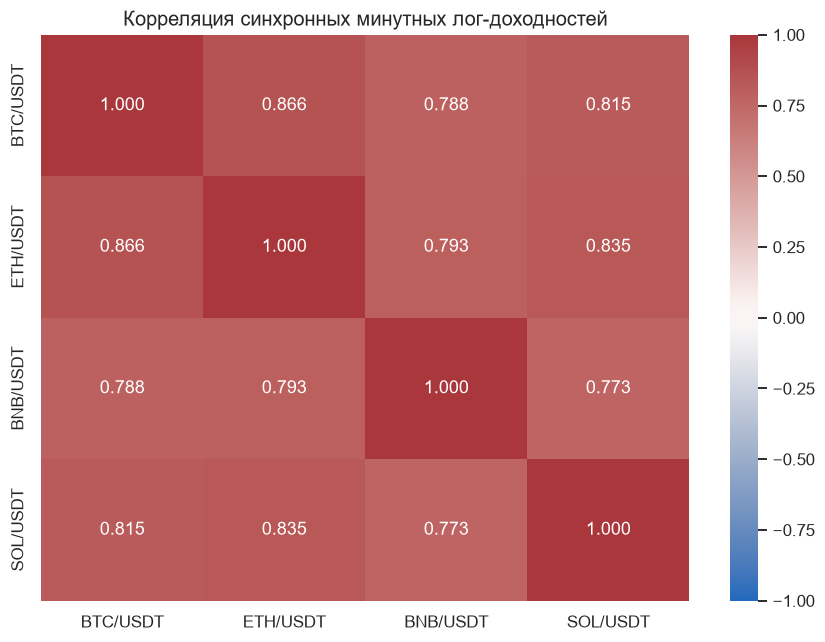

,BTC/USDT,ETH/USDT,BNB/USDT,SOL/USDT
BTC/USDT,1.0000,0.8661,0.7877,0.8147
ETH/USDT,0.8661,1.0000,0.7931,0.8353
BNB/USDT,0.7877,0.7931,1.0000,0.7727
SOL/USDT,0.8147,0.8353,0.7727,1.0000


In [9]:
contemporaneous_corr = log_returns.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    contemporaneous_corr,
    annot=True,
    fmt=".3f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Корреляция синхронных минутных лог-доходностей")
plt.tight_layout()
plt.show()

display(
    contemporaneous_corr.style.background_gradient(cmap="vlag", vmin=-1, vmax=1).format("{:.4f}")
)

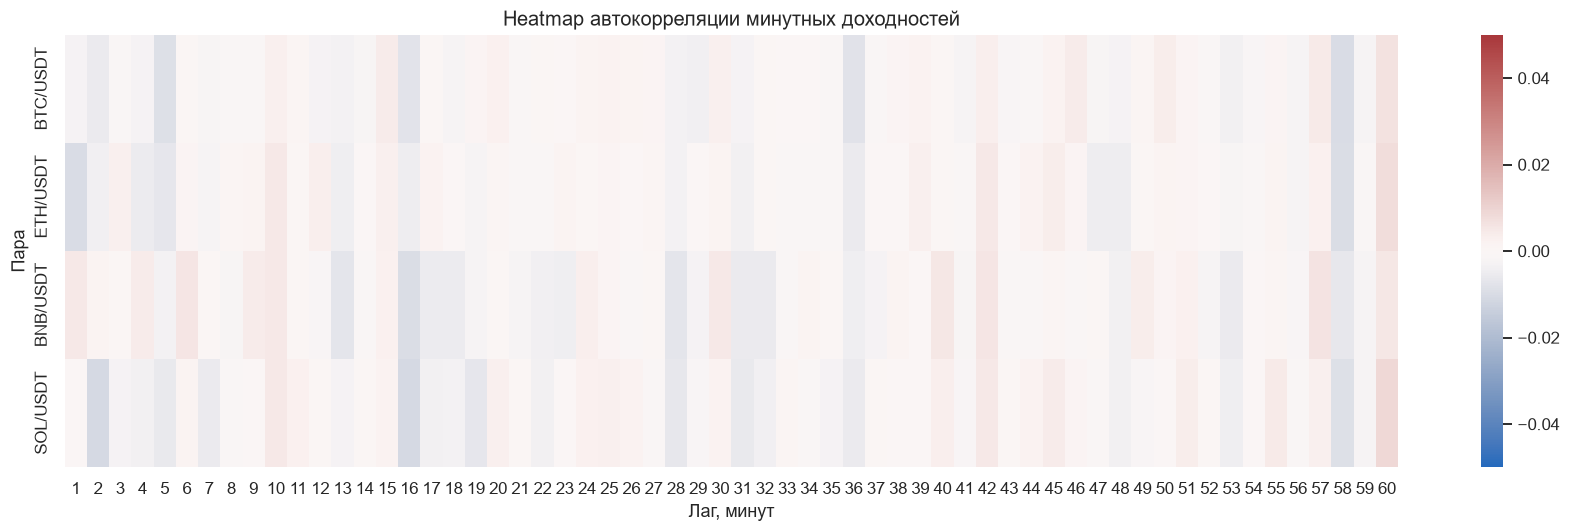

,лаг максимального |r|,корреляция
BTC/USDT,58,-0.0101
ETH/USDT,1,-0.0098
BNB/USDT,16,-0.0095
SOL/USDT,16,-0.0109


In [10]:
lag_range = np.arange(1, 61)
autocorrelation_matrix = pd.DataFrame(
    {
        column: [log_returns[column].autocorr(lag=int(lag)) for lag in lag_range]
        for column in log_returns.columns
    },
    index=lag_range,
).T

plt.figure(figsize=(16, 5))
sns.heatmap(autocorrelation_matrix, cmap="vlag", center=0, vmin=-0.05, vmax=0.05)
plt.title("Heatmap автокорреляции минутных доходностей")
plt.xlabel("Лаг, минут")
plt.ylabel("Пара")
plt.tight_layout()
plt.show()

strongest_autocorrelation = pd.DataFrame(
    {
        "лаг максимального |r|": autocorrelation_matrix.abs().idxmax(axis=1),
        "корреляция": [
            autocorrelation_matrix.loc[column, autocorrelation_matrix.loc[column].abs().idxmax()]
            for column in autocorrelation_matrix.index
        ],
    }
)
display(strongest_autocorrelation.style.format({"корреляция": "{:+.4f}"}))

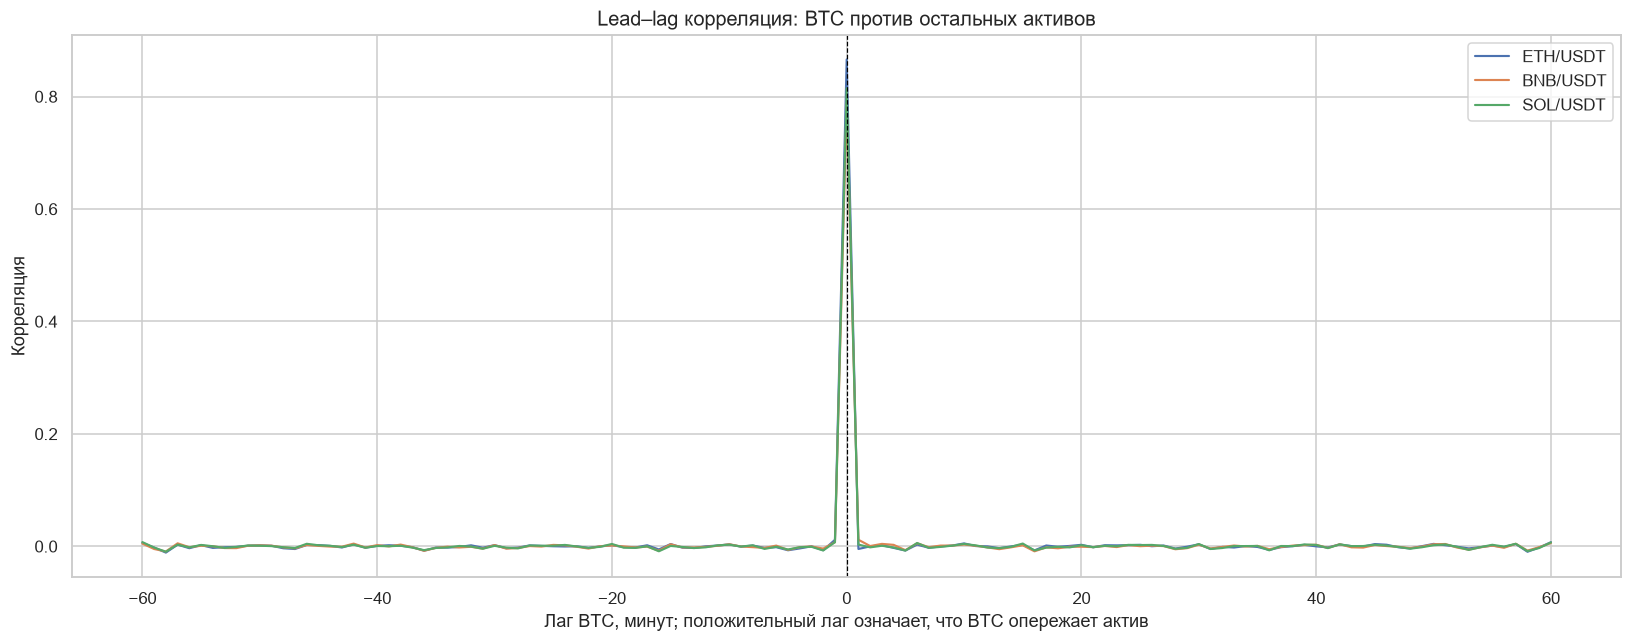

,синхронная корреляция,сильнейший ненулевой лаг,корреляция на лаге
актив,,,
ETH/USDT,+0.8661,-1.0000,+0.0117
BNB/USDT,+0.7877,+1.0000,+0.0117
SOL/USDT,+0.8147,-58.0000,-0.0096


In [11]:
LEAD_LAGS = np.arange(-60, 61)
btc_returns = log_returns["BTC/USDT"]
lead_lag = pd.DataFrame(index=LEAD_LAGS)
for asset in ["ETH/USDT", "BNB/USDT", "SOL/USDT"]:
    lead_lag[asset] = [btc_returns.shift(int(lag)).corr(log_returns[asset]) for lag in LEAD_LAGS]

lead_lag.plot(figsize=(15, 6), linewidth=1.4)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Lead–lag корреляция: BTC против остальных активов")
plt.xlabel("Лаг BTC, минут; положительный лаг означает, что BTC опережает актив")
plt.ylabel("Корреляция")
plt.tight_layout()
plt.show()

lead_lag_rows = []
for asset in lead_lag.columns:
    nonzero = lead_lag.loc[lead_lag.index != 0, asset]
    strongest_lag = int(nonzero.abs().idxmax())
    lead_lag_rows.append(
        {
            "актив": asset,
            "синхронная корреляция": lead_lag.loc[0, asset],
            "сильнейший ненулевой лаг": strongest_lag,
            "корреляция на лаге": lead_lag.loc[strongest_lag, asset],
        }
    )
display(pd.DataFrame(lead_lag_rows).set_index("актив").style.format("{:+.4f}"))

**Вывод.** Синхронные корреляции высоки: от 0.773 (BNB–SOL) до 0.866 (BTC–ETH), что подтверждает общий рыночный фактор. Максимальные автокорреляции на лагах 1–60 минут по модулю составляют лишь 0.0095–0.0109. Сильнейшие ненулевые связи BTC с другими активами также не превышают 0.012, тогда как синхронные равны 0.788–0.866. Значимого линейного опережения BTC не обнаружено; ненулевые лаги нельзя интерпретировать как причинность без отдельной walk-forward проверки.

## 7. Взаимосвязи признаков и внутридневная сезонность

Для примера детально рассматривается BTC. Высокая корреляция признаков означает возможную избыточность, а зависимость волатильности и объёма от часа UTC может быть полезным календарным признаком.

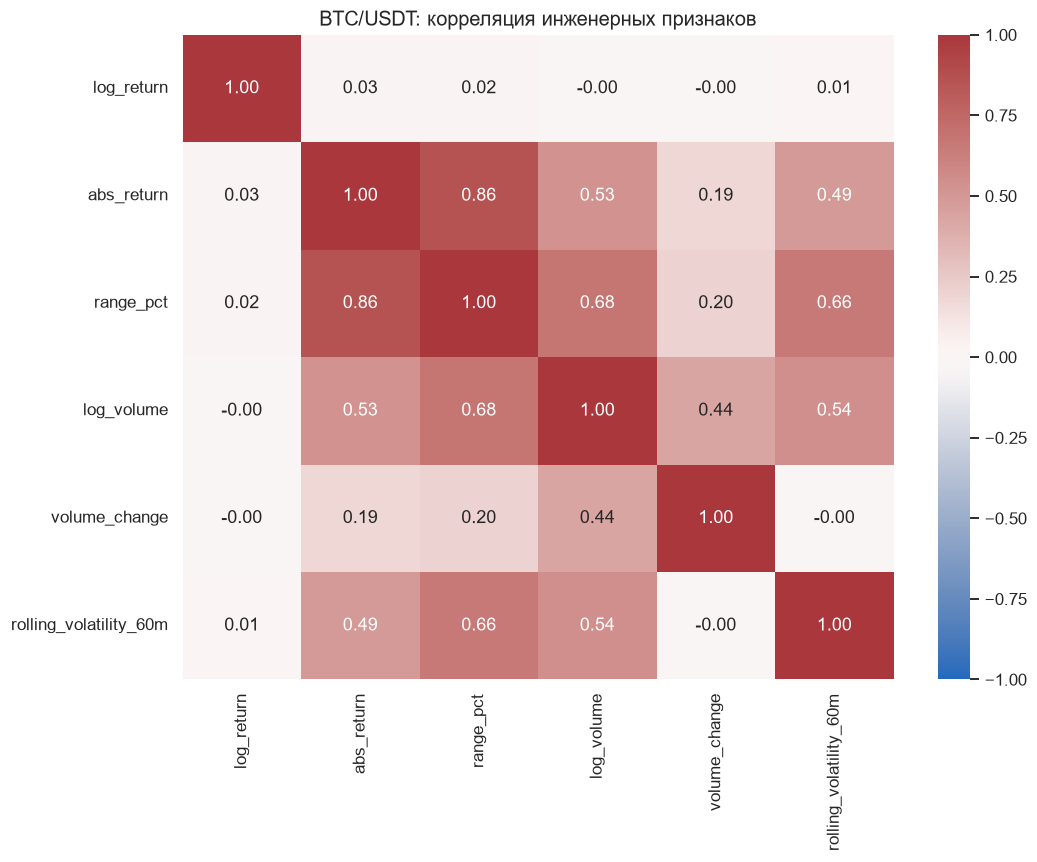

In [12]:
feature_columns = [
    "log_return",
    "abs_return",
    "range_pct",
    "log_volume",
    "volume_change",
    "rolling_volatility_60m",
]
btc_feature_corr = frames["BTC-USDT"][feature_columns].dropna().corr()

plt.figure(figsize=(10, 8))
sns.heatmap(btc_feature_corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("BTC/USDT: корреляция инженерных признаков")
plt.tight_layout()
plt.show()

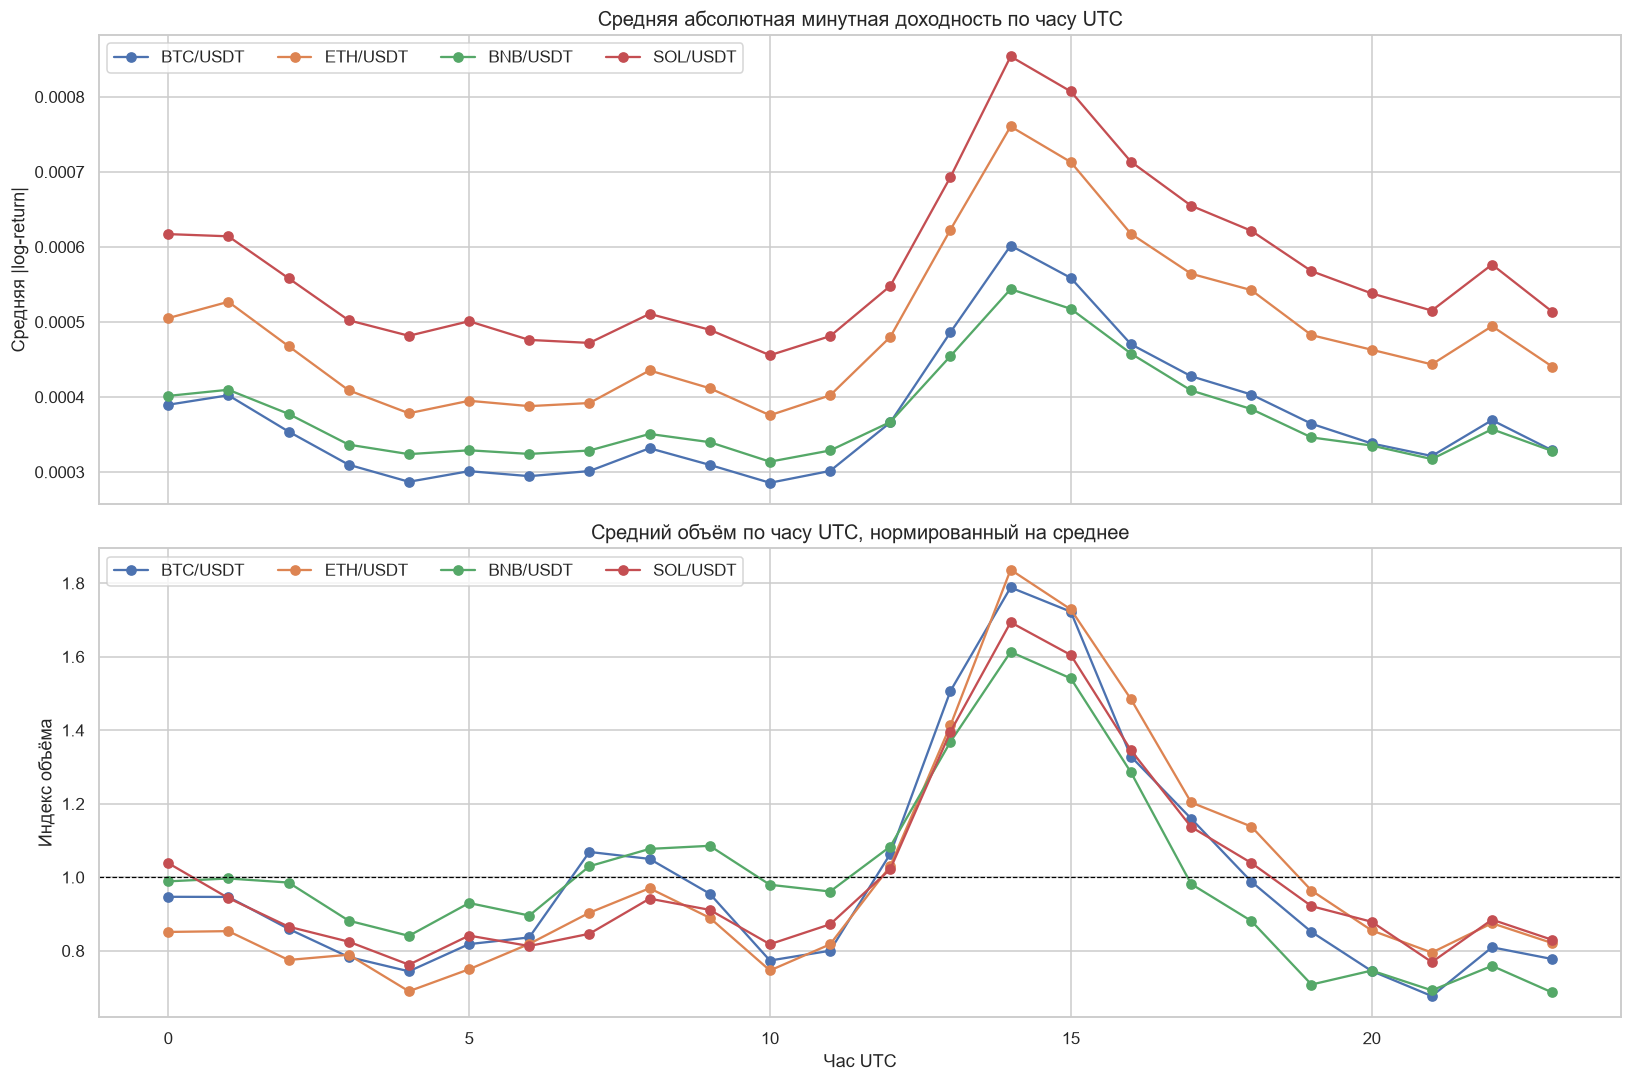

In [13]:
hourly_abs_return = pd.DataFrame(
    {
        DISPLAY_NAMES[symbol]: frame.groupby(frame.index.hour)["abs_return"].mean()
        for symbol, frame in frames.items()
    }
)
hourly_volume = pd.DataFrame(
    {
        DISPLAY_NAMES[symbol]: frame.groupby(frame.index.hour)["volume"].mean()
        for symbol, frame in frames.items()
    }
)
hourly_volume_index = hourly_volume / hourly_volume.mean()

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
hourly_abs_return.plot(ax=axes[0], marker="o")
axes[0].set_title("Средняя абсолютная минутная доходность по часу UTC")
axes[0].set_ylabel("Средняя |log-return|")
axes[0].legend(ncol=4)

hourly_volume_index.plot(ax=axes[1], marker="o")
axes[1].axhline(1.0, color="black", linestyle="--", linewidth=0.8)
axes[1].set_title("Средний объём по часу UTC, нормированный на среднее")
axes[1].set_xlabel("Час UTC")
axes[1].set_ylabel("Индекс объёма")
axes[1].legend(ncol=4)
plt.tight_layout()
plt.show()

**Вывод.** Для BTC абсолютная доходность и внутрисвечной диапазон сильно коррелируют (`r = 0.865`), а диапазон также связан со скользящей волатильностью (`r = 0.657`) и объёмом (`r = 0.684`). Эти признаки частично избыточны. У всех четырёх активов максимум средней абсолютной доходности и объёма приходится на 14:00 UTC; объём в этот час в 1.61–1.84 раза выше среднего. Поэтому час UTC и циклические признаки `sin/cos(hour)` следует включить в модели, но оценивать только на будущих временных отрезках.

## 8. Итоговые выводы для моделирования

1. Минутные OHLCV-данные полны, синхронизированы и не требуют импутации.
2. Ценовые уровни и `log(price)` содержат тренд и не должны использоваться как стационарный target без преобразования.
3. Логарифмические доходности являются предпочтительным target; для получения цены прогнозы можно накопить и экспоненцировать.
4. Доходности имеют тяжёлые хвосты и меняющуюся дисперсию, поэтому нужны квантильный прогноз, robust loss и отдельная оценка риска.
5. Линейная память направления на минутном TF ограничена, тогда как абсолютные доходности сохраняют память волатильности.
6. Между активами присутствует сильнее выраженная синхронная, чем лаговая зависимость; полезно обучать глобальную модель, но lead–lag сигнал должен подтверждаться out-of-sample.
7. Для первого моделирования разумны признаки доходности, диапазона, объёма, скользящей волатильности, часа UTC и рыночного контекста BTC.
8. Все дальнейшие эксперименты должны использовать purged walk-forward validation, комиссии и проскальзывание: случайное перемешивание временного ряда недопустимо.